In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import solve_banded


class BayesianGaussianDenoiser:

    def __init__(
        self,
        noise_std,
        signal_std,
        dt=15.0,
        tau=300.0
    ):

        self.noise_std = noise_std
        self.signal_std = signal_std
        self.dt = dt
        self.tau = tau

        # Temporal correlation
        self.rho = np.exp(-dt / tau)

    def denoise(self, y, prior_mean=0.0):

        y = np.asarray(y, dtype=float)

        n = len(y)

        # Noise variance
        noise_var = np.asarray(self.noise_std)**2

        if noise_var.ndim == 0:
            noise_var = np.full(n, noise_var)

        if noise_var.shape != (n,):
            raise ValueError("noise_std must be scalar or length n")

        if np.any(noise_var <= 0):
            raise ValueError("Noise variance must be positive")

        # Prior parameters
        sig2 = self.signal_std**2
        rho = self.rho

        # Prior precision matrix Q^-1
        prior_diag = np.full(
            n,
            (1 + rho**2) / (sig2 * (1-rho**2))
        )

        prior_diag[0] = 1 / (sig2 * (1-rho**2))
        prior_diag[-1] = 1 / (sig2 * (1-rho**2))

        prior_off = np.full(
            n-1,
            -rho / (sig2 * (1-rho**2))
        )

        # Posterior precision:
        # Q_post^-1 = Q^-1 + R^-1

        post_diag = prior_diag + 1/noise_var

        # Banded matrix representation
        ab = np.zeros((3, n))

        ab[0, 1:] = prior_off
        ab[1, :] = post_diag
        ab[2, :-1] = prior_off

        # Posterior mean
        rhs = (
            prior_diag * prior_mean
            + y / noise_var
        )

        posterior_mean = solve_banded(
            (1, 1), ab, rhs
        )

        # Posterior variance using LDL decomposition
        d = np.zeros(n)
        l = np.zeros(n-1)

        d[0] = post_diag[0]

        for i in range(n-1):

            l[i] = prior_off[i] / d[i]

            d[i+1] = (
                post_diag[i+1]
                - prior_off[i]**2 / d[i]
            )

        posterior_var = np.zeros(n)

        posterior_var[-1] = 1 / d[-1]

        for i in range(n-2, -1, -1):

            posterior_var[i] = (
                1/d[i]
                + l[i]**2 * posterior_var[i+1]
            )

        posterior_std = np.sqrt(posterior_var)

        return posterior_mean, posterior_std



In [2]:
import numpy as np
import matplotlib.pyplot as plt

def calculate_psd_std(ppsd, fmin=None, fmax=None):

    # Individual PSD estimates (dB)
    psd_db = np.asarray(ppsd.psd_values)

    # Period bins (seconds)
    periods = np.asarray(ppsd.period_bin_centers)

    # Convert period to frequency
    frequencies = 1.0 / periods

    # Sort frequencies in ascending order
    order = np.argsort(frequencies)

    frequencies = frequencies[order]
    psd_db = psd_db[:, order]

    # Select frequency band
    if fmin is None:
        fmin = frequencies.min()

    if fmax is None:
        fmax = frequencies.max()

    mask = (
        (frequencies >= fmin) &
        (frequencies <= fmax)
    )

    frequencies = frequencies[mask]
    psd_db = psd_db[:, mask]

    # Convert dB PSD to linear PSD
    psd_linear = 10**((psd_db)/ 10.0)*ppsd.ppsd_length
    #psd_linear = psd_db
    # Integrate PSD to obtain variance
    variance = np.trapezoid(
        psd_linear,
        x=frequencies,
        axis=1
    )

    # Standard deviation
    std = np.sqrt(variance)

    return std, variance


In [3]:
def denoise_dataset(
    data,
    noise_std,
    signal_std,
    dt=15.0,
    tau=300.0
):

    data = np.asarray(data)

    denoised = np.zeros_like(data, dtype=float)
    uncertainty = np.zeros_like(data, dtype=float)

    model = BayesianGaussianDenoiser(
        noise_std=noise_std,
        signal_std=signal_std,
        dt=dt,
        tau=tau
    )

    mean, std = model.denoise(data)

    denoised[:] = mean

    uncertainty[:] = std

    return denoised, uncertainty

In [4]:
3600*6*4/15

5760.0

In [13]:
from obspy.signal.spectral_estimation import PPSD
from mudpy.forward import lowpass
from mudpy.forward import highpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

stations=[46407,46404,46414,46403,46402,21420,51407,21416]
bayes_array=np.zeros((len(stations),int(3600*24/15)+1))
raw_array=np.zeros((len(stations),int(3600*24/15)+1))
for idx, station in enumerate(stations):

    file = f"/Users/seansantellanes/Documents/infragravity_waves/water_level_codes/NPZ_redux/{station}_psd.npz"
    ppsd = PPSD.load_npz(file)
    # Calculate standard deviation for every PSD window
    std, variance = calculate_psd_std(
        ppsd
    )
    print(30*"-")
    print(f"Starting at station: {station}")
    print("Median noise standard deviation:", np.nanmedian(std))
    print("Mean noise standard deviation:", np.nanmean(std))
    print("Standard deviation across windows:", np.nanstd(std))
    # Convert ObsPy UTCDateTime to Python datetime
    times_dt = [t.datetime for t in ppsd.times_processed]
    """ 
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(times_dt, std, linewidth=1)

    # Format x-axis as dates
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=365))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

    plt.ylabel("Noise standard deviation")
    plt.xlabel("Date (UTC)")
    plt.title("Noise variability over dataset")

    plt.xticks(rotation=30)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(8, 5))

    plt.hist(std[np.isfinite(std)], bins=50)

    plt.xlabel("Noise standard deviation")
    plt.ylabel("Frequency")
    plt.title("Distribution of noise standard deviation")

    plt.show() """
    # Exclude invalid PSD windows
    valid = np.isfinite(std)

    # Estimate representative background noise
    noise_std = np.median(std[valid])

    print("Estimated noise standard deviation:", noise_std)
    import pandas as pd
    file=f"/Users/seansantellanes/Documents/infragravity_waves/PTHA_codes/{station}/pressure_res_long.h5"
    ds=pd.read_hdf(file)
    ds["datetime"] = pd.to_datetime(ds.iloc[:,1],unit="s")
    #begin_time="2022-01-15"
    #end_time="2022-01-16"
    
    
    begin_time="2021-07-17"
    end_time="2021-07-18"

    #begin_time="2020-10-19"
    #end_time="2020-10-20"
    
    one_day=ds[ds["datetime"].between(begin_time,end_time)]
    data=one_day.iloc[:,0].to_numpy()
    # Example
    denoised, posterior_std = denoise_dataset(
        data,
        noise_std=noise_std,
        signal_std=0.5,
        dt=15.0,
        tau=400.0
    )

    time_plot=np.arange(0,len(data))*15
    raw_array[idx,:]=data
    bayes_array[idx,:]=denoised
    """     plt.plot(time_plot/3600,data,label="raw data")
    plt.plot(time_plot/3600,denoised,label="Bayesian Denoised data")

    plt.xlim([19,24])
    #plt.fill_between(time_plot/3600,denoised-posterior_std,denoised+posterior_std,alpha=0.2,label="95% credible interval")
    plt.legend()
    plt.ylabel("amplitude (m)")
    plt.xlabel("time (hrs)")
    plt.show() """
    """     from mudpy.forward import lowpass
    from mudpy.forward import highpass
    data_bp=lowpass(data,fcorner=[1/7200,1/120],fsample=1/15,order=4)
    denoised_bp=lowpass(denoised,fcorner=[1/7200,1/120],fsample=1/15,order=4)
    time_plot=np.arange(0,len(data))*15
    plt.plot(time_plot/3600,data_bp,label="raw data")
    plt.plot(time_plot/3600,denoised_bp,label="Bayesian Denoised data")

    plt.legend()
    plt.ylabel("amplitude (m)")
    plt.xlabel("time (hrs)")
    plt.xlim([19,24])
    plt.show() """
    print(30*"-")

------------------------------
Starting at station: 46407
Median noise standard deviation: 0.40344253641970096
Mean noise standard deviation: 0.46663353284569875
Standard deviation across windows: 0.18596057825170237
Estimated noise standard deviation: 0.40344253641970096
------------------------------
------------------------------
Starting at station: 46404
Median noise standard deviation: 0.4349906372650705
Mean noise standard deviation: 0.5084079914531096
Standard deviation across windows: 0.23012420762771374
Estimated noise standard deviation: 0.4349906372650705
------------------------------
------------------------------
Starting at station: 46414
Median noise standard deviation: 0.3161177763617512
Mean noise standard deviation: 0.34145273702232093
Standard deviation across windows: 0.23535766629579036
Estimated noise standard deviation: 0.3161177763617512
------------------------------
------------------------------
Starting at station: 46403
Median noise standard deviation: 0.

In [14]:
len(stations)

8

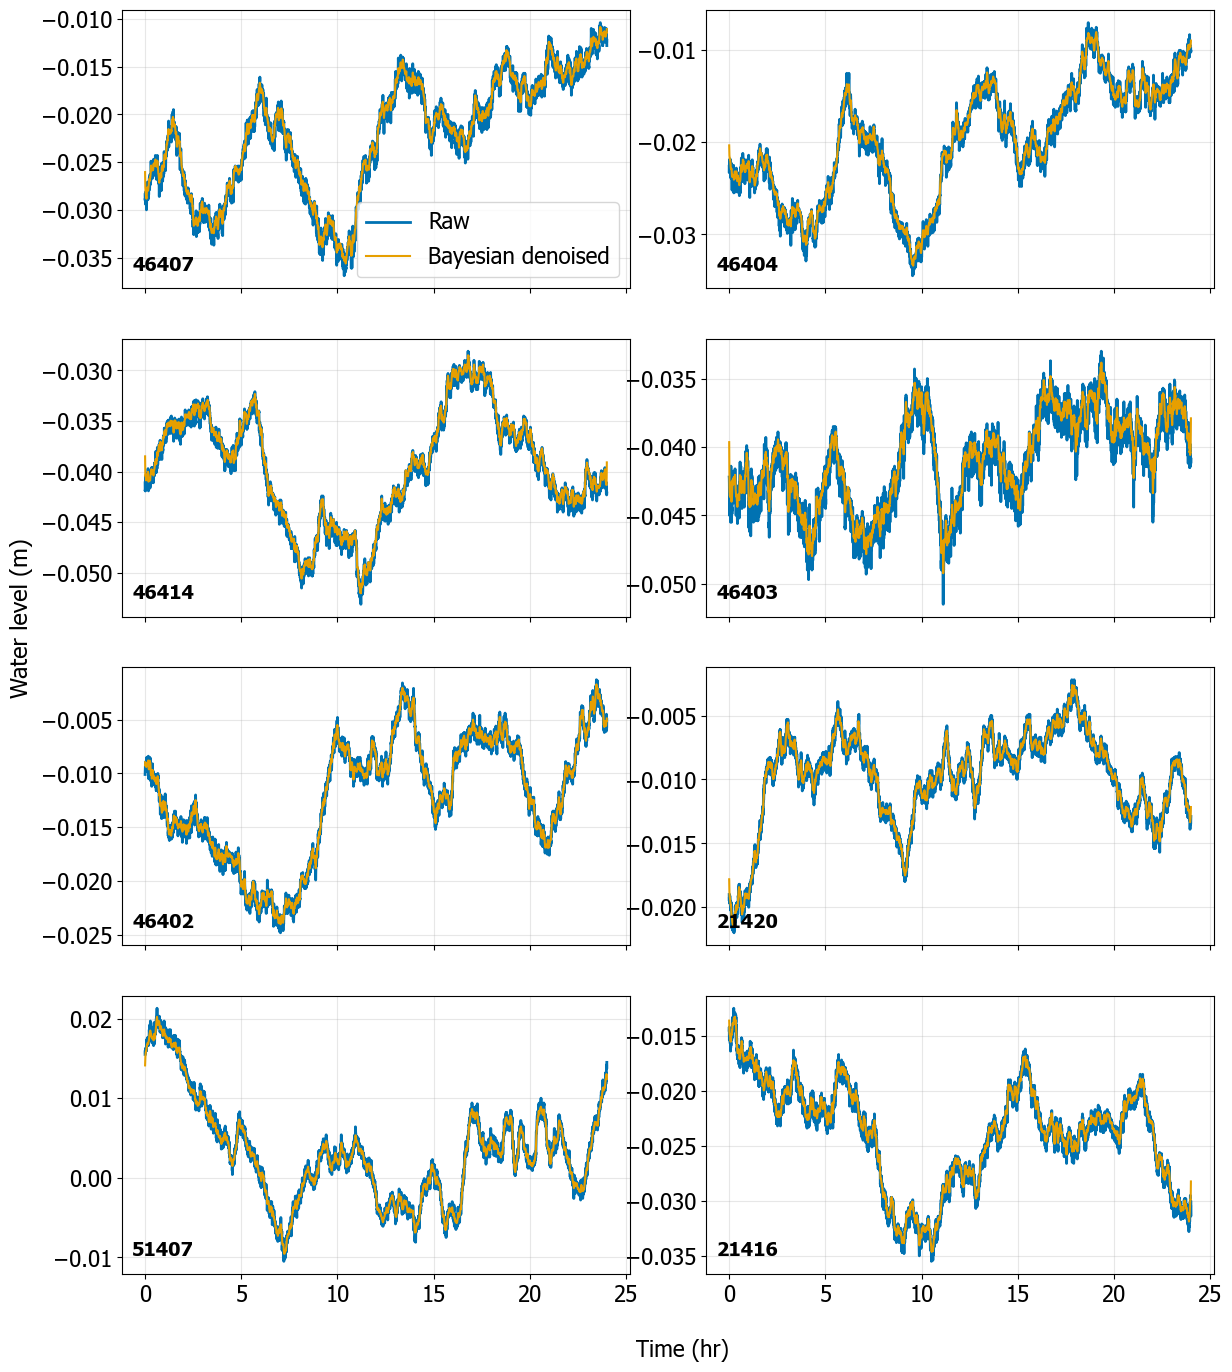

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
plt.rcParams.update({
    'font.size': 14,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 16,
    'figure.titlesize': 20
})
matplotlib.rc('font', family='Tahoma')
# Example data
# waveforms shape: (8, n_samples)
# times shape: (n_samples,)
# station_names: list of 8 station names
waveforms=bayes_array
raw_color = "#0072B2"
denoised_color = "#E69F00"
station_names=stations
times=time_plot/3600
fig, axes = plt.subplots(
    4, 2,
    figsize=(14, 16),
    sharex=True,
    sharey=False
)
axes = axes.flatten()
for i, ax in enumerate(axes):

    ax.plot(times, raw_array[i], linewidth=2,color=raw_color,label="Raw")
    ax.plot(times, waveforms[i], linewidth=1.5,color=denoised_color, label="Bayesian denoised")

    # Station name in bottom-left corner
    ax.text(
        0.02, 0.05,
        station_names[i],
        transform=ax.transAxes,
        fontsize=14,
        ha='left',
        va='bottom',
        fontweight='bold',
        color='black'
    )

    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='y')
        # Legend
    if i == 0:
        ax.legend(loc="best")



fig.supylabel("Water level (m)")
fig.supxlabel("Time (hr)", fontsize=16,y=0.035)
plt.subplots_adjust(
    right=0.88,
    left=0.10,
    bottom=0.09,
    hspace=0.18,
    wspace=0.15
)

plt.savefig(
    "/Users/seansantellanes/Documents/infragravity_waves/water_level_codes/Figures/toho_denoise.png",
    dpi=300
)

#plt.tight_layout()


/var/folders/03/t4njcc7x31b_r5f_0x9s1cd40000gn/T/ipykernel_2494/2508313397.py:31: RuntimeWarning: divide by zero encountered in divide
  return 1 / T


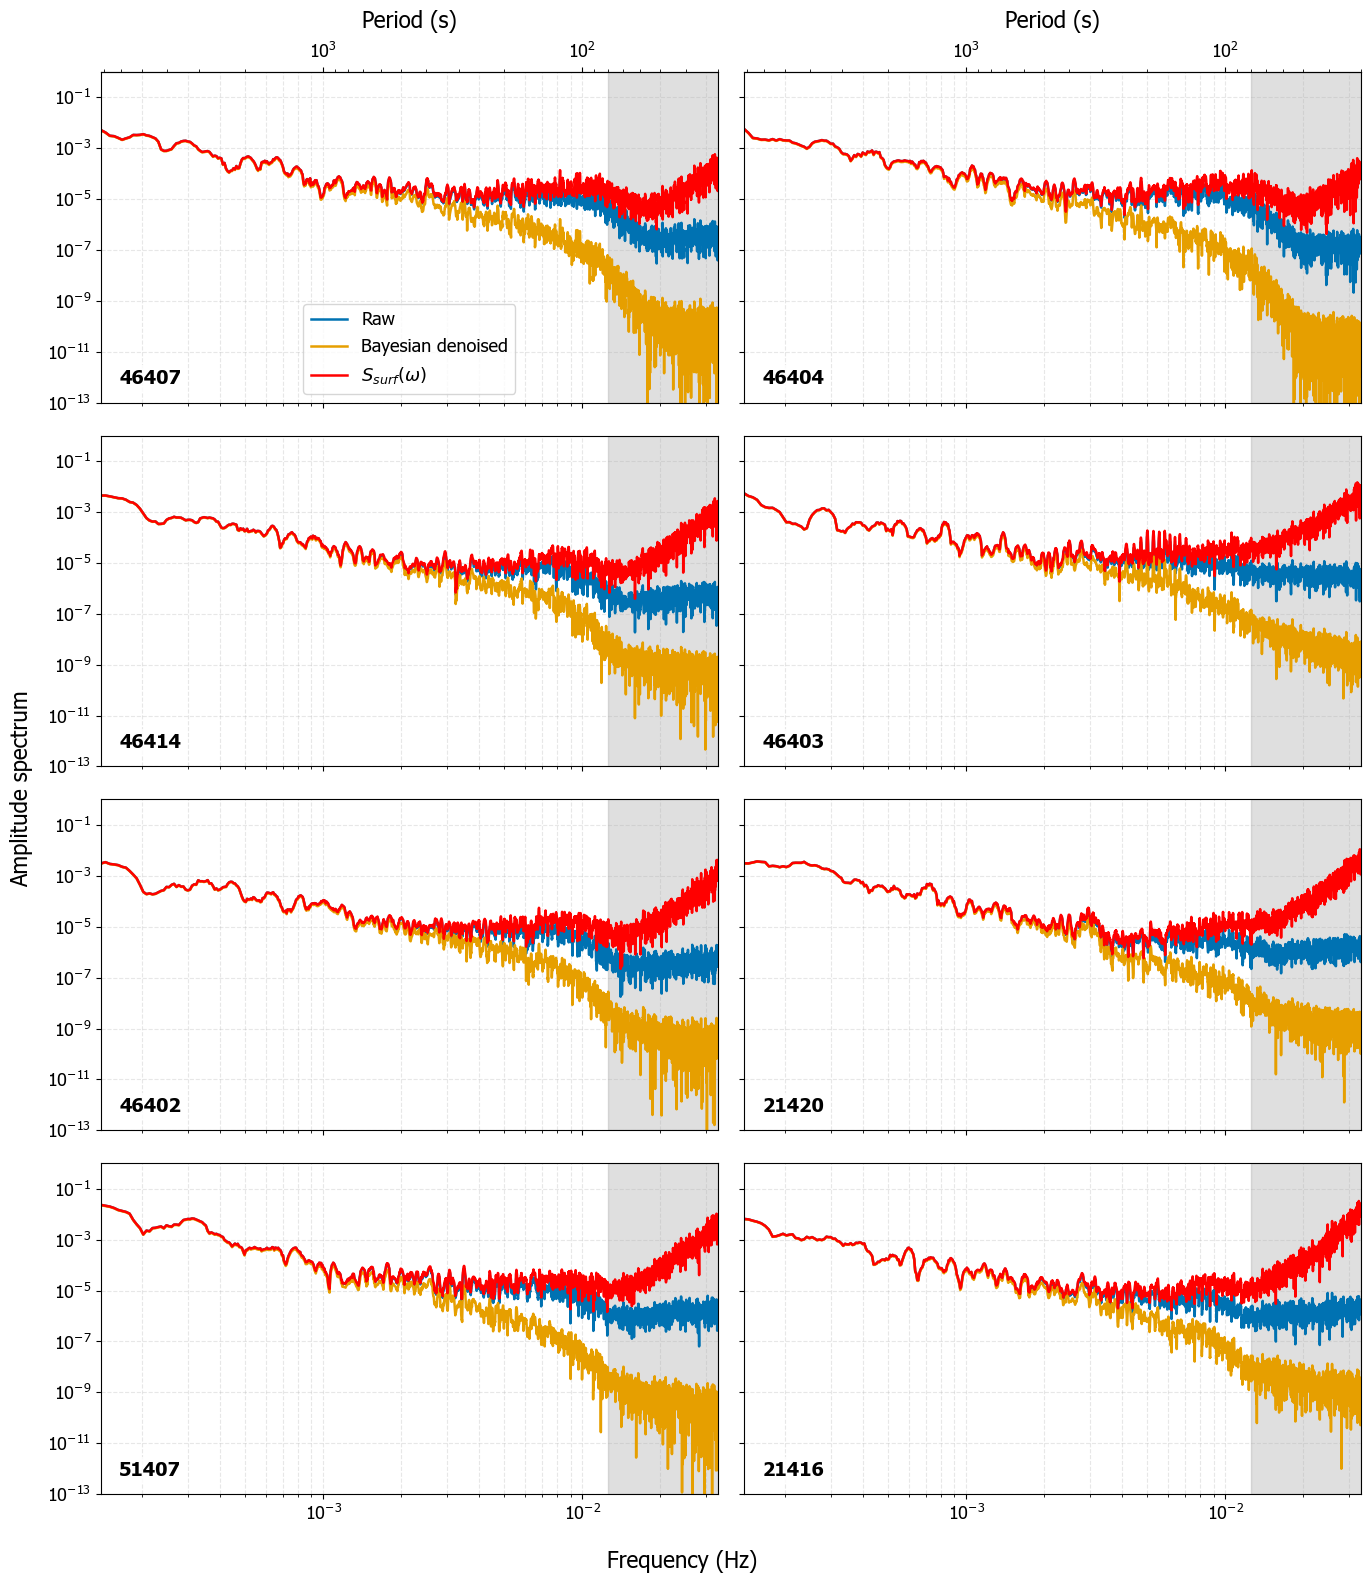

In [16]:
from multitaper import MTSpec
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 14,
    'axes.labelsize': 16,
    'axes.titlesize': 16,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 13,
})

fig, axes = plt.subplots(
    4, 2,
    figsize=(14, 16),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

# Colour-blind-friendly colours (blue/orange)
raw_color = "#0072B2"
denoised_color = "#E69F00"
surf_color="r"
def freq_to_period(f):
    return 1 / f

def period_to_freq(T):
    return 1 / T
depths=[3300,3738,4736,4522,4722,4877,4793,5812]
for i, ax in enumerate(axes):

    psd_raw = MTSpec(raw_array[i], nw=3.5, kspec=5, dt=15.0)
    psd_de = MTSpec(waveforms[i], nw=3.5, kspec=5, dt=15.0)

    freq_raw = psd_raw.freq
    idx = np.where(freq_raw > 0)
    freq = freq_raw[idx]

    qi0_raw = psd_raw.qiinv()[0]
    qi0_de = psd_de.qiinv()[0]
    depth=depths[i]
    k=(2*np.pi*freq)/np.sqrt(9.81*depth)
    spec_surf=np.cosh(k*depth)**2*qi0_raw[idx]
    ax.loglog(
        freq, qi0_raw[idx],
        color=raw_color,
        linewidth=1.8,
        label="Raw"
    )

    ax.loglog(
        freq, qi0_de[idx],
        color=denoised_color,
        linewidth=1.8,
        label="Bayesian denoised"
    )
    ax.loglog(
        freq, spec_surf,
        color=surf_color,
        linewidth=1.8,
        label=r"$S_{surf}(\omega)$"
    )
    ax.set_xlim(1/7200, 1/30)
    ax.set_ylim(1e-13, 1)
    ax.grid(True, which="both", alpha=0.3, linestyle="--")
    ax.axvspan(
    1/80,
    1/30,
    color="gray",
    alpha=0.25,
    zorder=0
    )
    # Station label inside subplot
    ax.text(
        0.03, 0.1,
        station_names[i],
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.8,
            pad=3
        )
    )

    # Legend only on first subplot
    if i == 0:
        ax.legend(loc="lower center", frameon=True)

# Period axis only across the top of the figure
ax_top = axes[0].secondary_xaxis(
    'top',
    functions=(freq_to_period, period_to_freq)
)
ax_top.set_xlabel("Period (s)", fontsize=16, labelpad=10)
ax_top = axes[1].secondary_xaxis(
    'top',
    functions=(freq_to_period, period_to_freq)
)
ax_top.set_xlabel("Period (s)", fontsize=16, labelpad=10)

# Shared labels
fig.supxlabel("Frequency (Hz)", fontsize=16)
fig.supylabel("Amplitude spectrum", fontsize=16)

plt.tight_layout()

plt.savefig(
    "/Users/seansantellanes/Documents/infragravity_waves/water_level_codes/Figures/rabin_denoise_amp_spec.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()